# E-Commerce Return Prediction: Exploratory Data Analysis (EDA)

## Dataset Summary:
- **Source**: `ziadatalabs/FreeEcommerceOrders50M`
- **Total Records**: 50,000,000 rows
- **Columns Identified**:
  - Identifiers: `order_id`, `customer_id`, `product_id`
  - Temporal: `order_date`
  - Categorical: `product_category`, `payment_method`, `order_status`, `discount_applied`
  - Numerical: `quantity`, `unit_price`, `order_total`, `shipping_cost`
- **Objective**: Explore attributes, verify data quality, understand class distribution, and identify key drivers for order returns (`order_status == 'returned'`).

**Loading HF Dataset Locally**

In [2]:
from datasets import load_dataset
import os
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"


ds = load_dataset(
    "ziadatalabs/FreeEcommerceOrders50M",
    split="train",
    streaming=True
)

# Display the first 5 records without downloading the entire dataset
for i, row in enumerate(ds):
    print(row)
    if i == 4:
        break

{'order_id': 'ORD0000000000', 'customer_id': 'CUST06438651', 'order_date': '2024-12-03', 'product_category': 'grocery', 'product_id': 'SKU-GRO-34044', 'quantity': 5, 'unit_price': 4.83, 'order_total': 31.59, 'payment_method': 'credit_card', 'shipping_cost': 7.44, 'order_status': 'delivered', 'discount_applied': False}
{'order_id': 'ORD0000000001', 'customer_id': 'CUST04024143', 'order_date': '2025-03-19', 'product_category': 'home', 'product_id': 'SKU-HOM-22793', 'quantity': 1, 'unit_price': 101.25, 'order_total': 101.25, 'payment_method': 'credit_card', 'shipping_cost': 0.0, 'order_status': 'delivered', 'discount_applied': False}
{'order_id': 'ORD0000000002', 'customer_id': 'CUST08227616', 'order_date': '2025-06-16', 'product_category': 'grocery', 'product_id': 'SKU-GRO-47426', 'quantity': 1, 'unit_price': 13.88, 'order_total': 18.06, 'payment_method': 'credit_card', 'shipping_cost': 4.18, 'order_status': 'processing', 'discount_applied': False}
{'order_id': 'ORD0000000003', 'customer

**Environment Setup & Streaming Ingestion**

In [3]:
import warnings
warnings.filterwarnings('ignore')

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

# Set visualization style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Load streaming dataset
print("Initializing dataset stream...")
ds = load_dataset("ziadatalabs/FreeEcommerceOrders50M", split="train", streaming=True)

# Stream a statistically representative sample (500,000 rows)
sample_data = list(itertools.islice(ds.shuffle(seed=42, buffer_size=100_000),500_000))
df = pd.DataFrame(sample_data)

print(f"Sample loaded successfully. Shape: {df.shape}")
df.head()

Initializing dataset stream...


'[WinError 10054] An existing connection was forcibly closed by the remote host' thrown while requesting GET https://huggingface.co/datasets/ziadatalabs/FreeEcommerceOrders50M/resolve/d4f02e6ba4fd10c1c03a544d98f289908d427750/ecommerce_50M.parquet
Retrying in 1s [Retry 1/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting GET https://huggingface.co/datasets/ziadatalabs/FreeEcommerceOrders50M/resolve/d4f02e6ba4fd10c1c03a544d98f289908d427750/ecommerce_50M.parquet
Retrying in 2s [Retry 2/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting GET https://huggingface.co/datasets/ziadatalabs/FreeEcommerceOrders50M/resolve/d4f02e6ba4fd10c1c03a544d98f289908d427750/ecommerce_50M.parquet
Retrying in 4s [Retry 3/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting GET https://huggingface.co/datasets/ziadatalabs/FreeEcommerceOrders50M/resolve/d4f02e6ba4fd10c1c03a544d98f289908d427750/ecommerce_50M.parquet
Retrying in 8s [Retry 4/5].


Sample loaded successfully. Shape: (500000, 12)


,order_id,customer_id,order_date,product_category,product_id,quantity,unit_price,order_total,payment_method,shipping_cost,order_status,discount_applied
0,ORD0000045262,CUST06864049,2025-01-18,sports,SKU-SPO-37042,2,219.38,438.76,credit_card,0.00,delivered,True
1,ORD0000049850,CUST03864946,2024-03-01,books,SKU-BOO-21919,3,11.66,43.58,paypal,8.60,delivered,False
2,ORD0000030394,CUST05420295,2024-03-18,beauty,SKU-BEA-07810,1,11.09,19.13,paypal,8.04,delivered,False
3,ORD0000090177,CUST04161341,2024-04-27,beauty,SKU-BEA-30726,1,48.33,56.97,credit_card,8.64,delivered,False
4,ORD0000095569,CUST04599595,2024-05-27,home,SKU-HOM-37573,1,186.36,186.36,paypal,0.00,delivered,False


### Dataset Sampling

A sample of 500,000 records was loaded from the streaming dataset for exploratory analysis.

The analysis is based on this sample rather than the entire 50-million-record dataset.

## 1. Initial Data Validation

This section examines the dataset's structure, date coverage, order-status distribution, missing values, duplicate records, and numerical ranges.

In [4]:
# Check dataset structure
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (500000, 12)

Column names:
['order_id', 'customer_id', 'order_date', 'product_category', 'product_id', 'quantity', 'unit_price', 'order_total', 'payment_method', 'shipping_cost', 'order_status', 'discount_applied']

Data types:
order_id                str
customer_id             str
order_date              str
product_category        str
product_id              str
quantity              int64
unit_price          float64
order_total         float64
payment_method          str
shipping_cost       float64
order_status            str
discount_applied       bool
dtype: object


**Result: Dataset Structure**

The sample contains 500,000 rows and 12 columns. The dataset includes three identifiers, one date column, four numerical features, and four categorical or Boolean attributes. The numerical columns are stored in appropriate numeric types, while the date column requires conversion to a datetime format for temporal analysis.

In [5]:
# Check date coverage
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

print("\nDate coverage:")
print("Earliest order:", df["order_date"].min())
print("Latest order:", df["order_date"].max())
print("Invalid dates:", df["order_date"].isna().sum())


Date coverage:
Earliest order: 2024-01-01 00:00:00
Latest order: 2025-12-30 00:00:00
Invalid dates: 0


**Result: Temporal Coverage**

The sampled records span January 1, 2024, to December 30, 2025. No invalid dates were detected after conversion to datetime format, allowing the records to be grouped by month and year for temporal analysis.

In [6]:
# Inspect order status distribution
print("\nOrder status distribution:")
print(df["order_status"].value_counts(dropna=False))

print("\nOrder status proportions (%):")
print(
    (df["order_status"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)


Order status distribution:
order_status
delivered     354803
shipped        50029
returned       45209
processing     30064
cancelled      19895
Name: count, dtype: int64

Order status proportions (%):
order_status
delivered     70.96
shipped       10.01
returned       9.04
processing     6.01
cancelled      3.98
Name: proportion, dtype: float64


**Result: Order-Status Distribution**

The status distribution is imbalanced, with delivered orders forming the majority. The returned-status proportion here is calculated over all sampled records, not just delivered and returned orders.

In [46]:
# Check missing values
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))


Missing values:
order_id                 0
customer_id              0
order_date               0
product_category         0
product_id               0
quantity                 0
unit_price               0
order_total              0
payment_method           0
shipping_cost            0
order_status             0
discount_applied         0
is_marked_returned       0
calculated_item_value    0
total_difference         0
shipping_group           0
order_value_range        0
order_month              0
dtype: int64


**Result: Missing Values**

No missing values were found in any of the 12 columns. Therefore, missing-value imputation is not required for the sampled data in its current form. This check does not rule out other data-quality issues, such as incorrect values or inconsistencies between columns.

In [8]:
# Check duplicate records and identifiers
print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate order IDs:", df["order_id"].duplicated().sum())
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())


Exact duplicate rows: 0
Duplicate order IDs: 0
Duplicate customer IDs: 12261


**Result: Duplicate Records**

No exact duplicate rows or duplicate order IDs were detected. Customer IDs do repeat, which is expected when a customer places multiple orders and does not by itself indicate a data-quality problem.

In [9]:
# Check numerical ranges
numeric_cols = [
    "quantity", "unit_price", "order_total", "shipping_cost"
]

print("\nNumerical summary:")
display(df[numeric_cols].describe().T)


Numerical summary:


,count,mean,std,min,25%,50%,75%,max
quantity,500000.0,1.919200,1.246638,1.00,1.00,1.00,2.00,6.00
unit_price,500000.0,106.945170,141.546994,2.03,21.97,51.78,124.70,1157.48
order_total,500000.0,207.324509,346.852755,6.38,40.97,82.94,218.40,6172.80
shipping_cost,500000.0,2.469555,3.494922,0.00,0.00,0.00,5.74,9.99


**Result: Numerical Summary**

The median quantity is 1, while the median unit price and order total are 51.78 and 82.94, respectively. Shipping costs have a median of zero and a maximum of 9.99. The mean order total (207.32) is substantially higher than its median, suggesting a right-skewed distribution influenced by high-value orders.

These differences justify examining feature distributions and potential outliers in the following section.

### Verifying the Unit of Observation

Before interpreting order-level patterns, verify whether each row represents a unique order or an individual product within an order. This distinction affects how counts and return percentages should be interpreted.

In [11]:
print("Total rows:", len(df))
print("Unique order IDs:", df["order_id"].nunique())
print("Unique product IDs:", df["product_id"].nunique())

Total rows: 500000
Unique order IDs: 500000
Unique product IDs: 275880


In [13]:
print("Orders with multiple rows:", (df.groupby("order_id").size() > 1).sum())

print("\nRows per order:")
print(df.groupby("order_id").size().value_counts().sort_index().head(10))

Orders with multiple rows: 0

Rows per order:
1    500000
Name: count, dtype: int64


**Result: One Row per Order**

All 500,000 rows have unique order IDs, and no order contains multiple rows. Therefore, each row in this sample represents one order record rather than a separate product line within a multi-row order.

The sample contains 275,880 unique product IDs, indicating that products can appear across multiple orders.

## Examine numerical feature distributions

### Distribution of Numerical Features

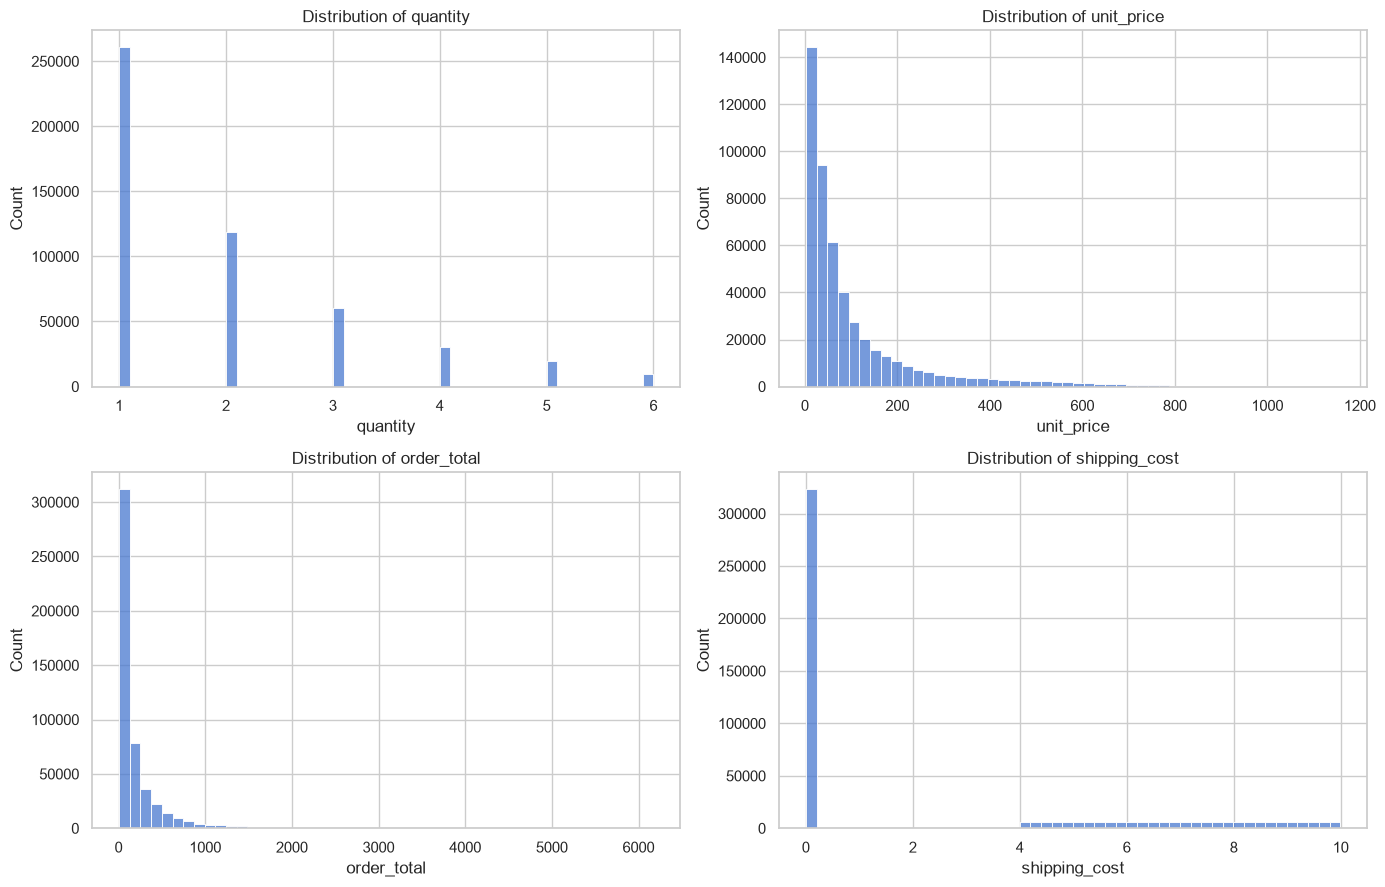

In [16]:
numeric_features = [
    "quantity",
    "unit_price",
    "order_total",
    "shipping_cost"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for feature, ax in zip(numeric_features, axes.flat):
    sns.histplot(data=df, x=feature, bins=50, ax=ax)
    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

**Result: Feature Distributions**

The numerical summaries suggest that unit price and order total have substantial right tails, with their means exceeding their medians. Quantity is concentrated around smaller values, while shipping cost includes a large number of zero-cost records.

These distributional differences suggest that means alone may not fully describe the data and that medians and boxplots are useful complementary summaries.

### Boxplots and Potential Outliers

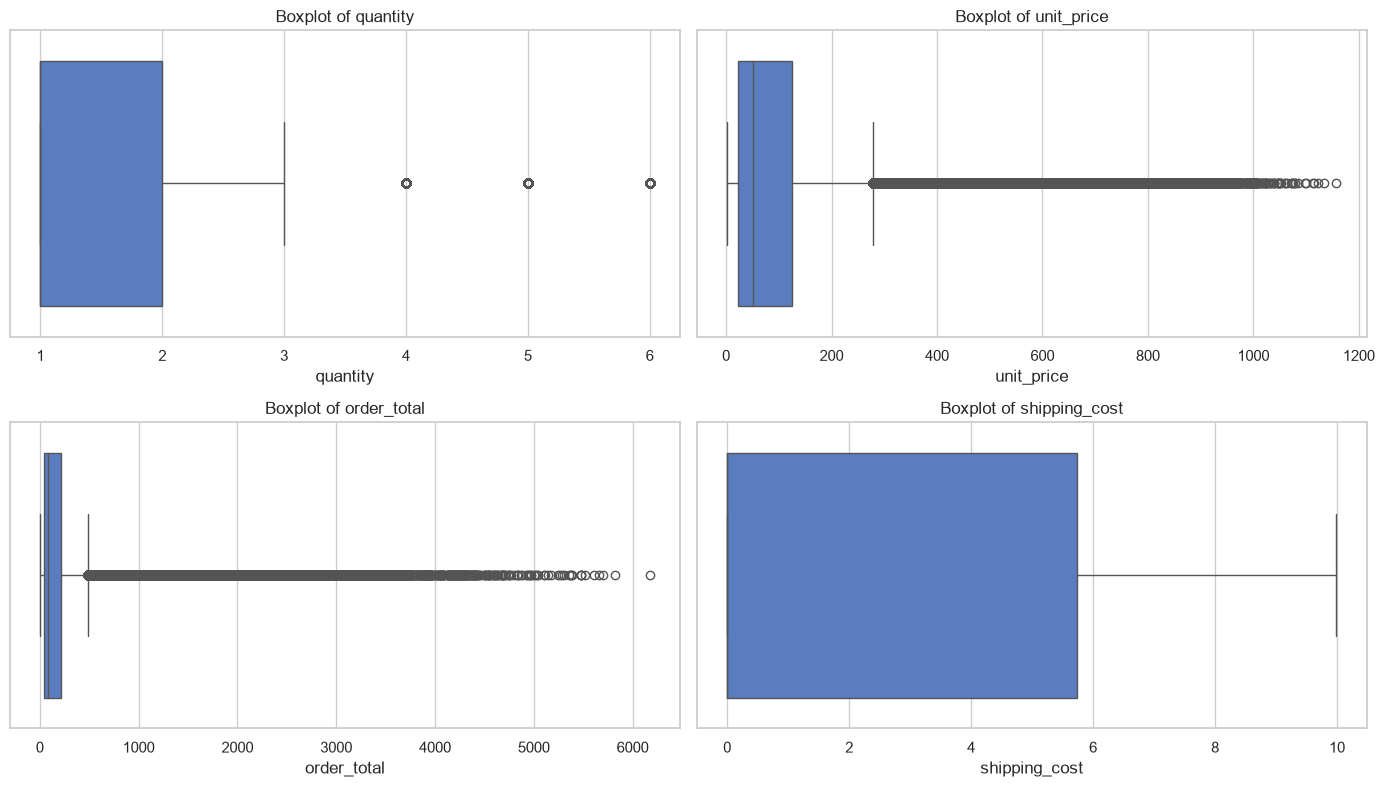

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for feature, ax in zip(numeric_features, axes.flat):
    sns.boxplot(data=df, x=feature, ax=ax)
    ax.set_title(f"Boxplot of {feature}")

plt.tight_layout()
plt.show()

**Result: Potential Outliers**

The boxplots provide a complementary view of the spread and extreme values in the numerical features. Given the large differences between the means and medians of unit price and order total, high-value observations warrant attention. However, outliers should not be removed without evidence that they are erroneous.

## Examine categorical features

### Category Counts and Observed Return-Status Rates

Compare product category, payment method, and discount status with the recorded order outcome. For this exploratory comparison, `is_marked_returned` equals 1 when `order_status` is `returned` and 0 otherwise.

These initial rates use all sampled orders as the denominator. Because shipped, processing, and cancelled orders are not equivalent to completed outcomes, the rates should be treated as preliminary descriptive comparisons.

In [18]:
df["is_marked_returned"] = (df["order_status"] == "returned").astype(int)

categorical_features = [
    "product_category",
    "payment_method",
    "discount_applied"
]

for feature in categorical_features:
    print(f"\n{'=' * 50}")
    print(f"Feature: {feature}")

    print("\nCategory counts:")
    print(df[feature].value_counts(dropna=False))

    summary = (
        df.groupby(feature, dropna=False)
        .agg(
            order_count=("order_id", "size"),
            marked_returned=("is_marked_returned", "sum"),
            observed_returned_fraction=(
                "is_marked_returned", "mean"
            )
        )
        .sort_values("observed_returned_fraction", ascending=False)
    )

    summary["observed_returned_pct"] = (
        summary["observed_returned_fraction"] * 100
    ).round(2)

    display(summary)


Feature: product_category

Category counts:
product_category
clothing       109694
electronics     79701
home            70452
books           54721
grocery         50107
beauty          50074
sports          45025
toys            40226
Name: count, dtype: int64


,order_count,marked_returned,observed_returned_fraction,observed_returned_pct
product_category,,,,
clothing,109694,19490,0.177676,17.77
electronics,79701,8771,0.110049,11.00
sports,45025,3977,0.088329,8.83
home,70452,4930,0.069977,7.00
toys,40226,2593,0.064461,6.45
beauty,50074,2928,0.058473,5.85
books,54721,1731,0.031633,3.16
grocery,50107,789,0.015746,1.57



Feature: payment_method

Category counts:
payment_method
credit_card    220327
debit_card     119720
paypal          89956
bnpl            39969
gift_card       30028
Name: count, dtype: int64


,order_count,marked_returned,observed_returned_fraction,observed_returned_pct
payment_method,,,,
bnpl,39969,3672,0.091871,9.19
debit_card,119720,10941,0.091388,9.14
credit_card,220327,19852,0.090102,9.01
gift_card,30028,2695,0.089750,8.97
paypal,89956,8049,0.089477,8.95



Feature: discount_applied

Category counts:
discount_applied
False    384585
True     115415
Name: count, dtype: int64


,order_count,marked_returned,observed_returned_fraction,observed_returned_pct
discount_applied,,,,
True,115415,10758,0.093211,9.32
False,384585,34451,0.089580,8.96


**Result: Categorical Comparison**

Product categories differ considerably in their observed returned-status proportions. Clothing has the highest proportion in the sample, with approximately 17.77% of its records marked returned, while grocery has the lowest, at approximately 1.57%.

These differences suggest that product category may be informative for further investigation. The initial rates include every order status, so the later comparison restricted to delivered and returned orders provides a more focused analysis.

### Visual Comparison of Categorical Features

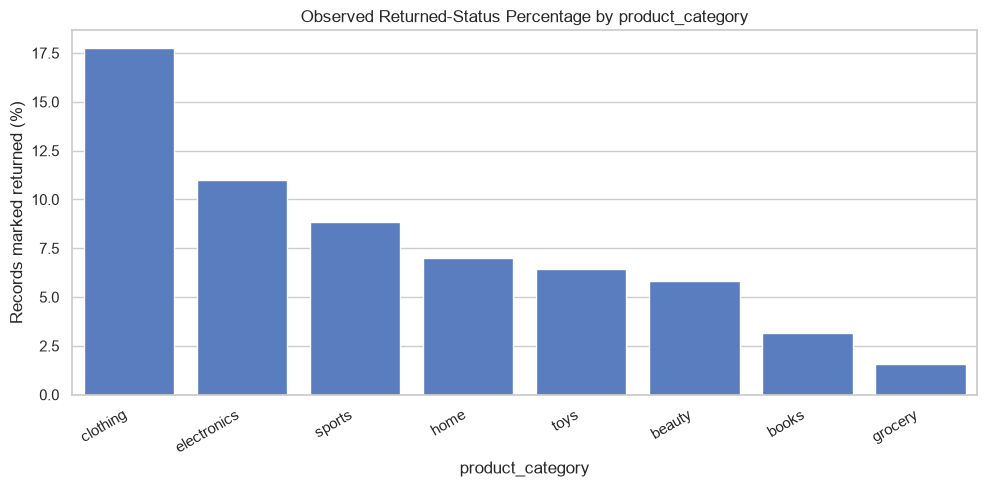

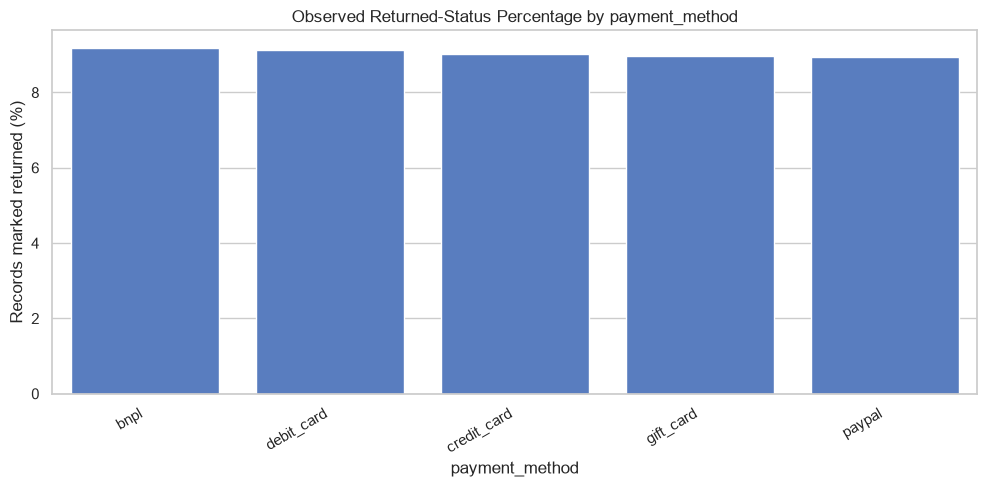

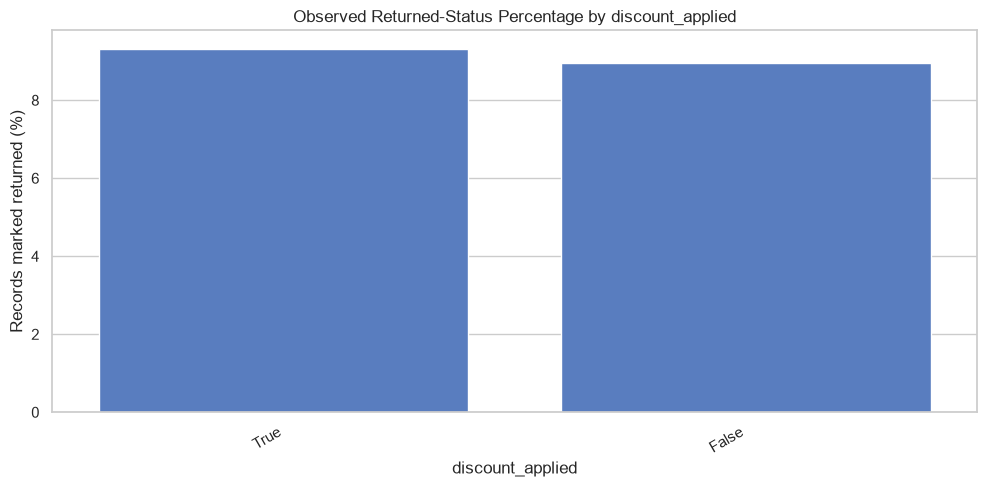

In [19]:
for feature in categorical_features:
    rates = (
        df.groupby(feature, dropna=False)["is_marked_returned"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 5))
    sns.barplot(x=rates.index.astype(str), y=rates.values)

    plt.title(
        f"Observed Returned-Status Percentage by {feature}"
    )
    plt.xlabel(feature)
    plt.ylabel("Records marked returned (%)")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

**Result: Categorical Visualizations**

The bar plots make differences in observed returned-status proportions easier to compare across categories. These are descriptive associations only and do not establish that a particular payment method, product category, or discount causes an order to be returned.

### Consistency Between Order Total and Item Value

Check whether `order_total` matches the calculated item value, obtained by multiplying `quantity` by `unit_price`. Differences may reflect shipping charges, discounts, taxes, or other components of the order total, so they should be investigated before assuming that the columns are inconsistent.

In [21]:
df["calculated_item_value"] = (
    df["quantity"] * df["unit_price"]
)

df["total_difference"] = (
    df["order_total"] - df["calculated_item_value"]
)

display(
    df[
        [
            "quantity",
            "unit_price",
            "order_total",
            "calculated_item_value",
            "total_difference"
        ]
    ].head(10)
)

print(
    "Correlation between order_total and quantity × unit_price:",
    df["order_total"].corr(df["calculated_item_value"])
)

print(
    "Rows where total differs from quantity × unit_price:",
    (~np.isclose(
        df["order_total"],
        df["calculated_item_value"],
        rtol=0.01,
        atol=0.02
    )).sum()
)

,quantity,unit_price,order_total,calculated_item_value,total_difference
0,2,219.38,438.76,438.76,0.00
1,3,11.66,43.58,34.98,8.60
2,1,11.09,19.13,11.09,8.04
3,1,48.33,56.97,48.33,8.64
4,1,186.36,186.36,186.36,0.00
5,2,73.04,146.08,146.08,0.00
6,1,49.18,57.77,49.18,8.59
7,3,22.72,68.16,68.16,0.00
8,3,471.98,1415.94,1415.94,0.00
9,1,15.28,24.92,15.28,9.64


Correlation between order_total and quantity × unit_price: 0.9999559299401497
Rows where total differs from quantity × unit_price: 176748


**Result: Order-Total Consistency**

The sample contains records where `order_total` differs from `quantity × unit_price`. For example, some records have a positive difference between the recorded total and the calculated item value, while others match exactly.

This suggests that the order total may include additional components beyond the item value. The difference should not automatically be classified as an error without further information about the dataset's pricing rules.

### Order-Status Counts by Month and Year

Examine how the number of records in each order status varies over time. Monthly counts show the volume of each status, while yearly percentages help compare status composition across years without relying solely on total counts.

In [22]:
status_counts = pd.crosstab(
    df["order_date"].dt.to_period("M"),
    df["order_status"]
)

display(status_counts)

print("\nStatus distribution by year:")
display(
    pd.crosstab(
        df["order_date"].dt.year,
        df["order_status"],
        normalize="index"
    ).mul(100).round(2)
)

order_status,cancelled,delivered,processing,returned,shipped
order_date,,,,,
2024-01,833,14926,1257,1851,2129
2024-02,745,14093,1210,1872,1984
2024-03,888,15188,1270,1927,2158
2024-04,784,14325,1174,1842,2074
2024-05,879,15142,1244,1906,2104
2024-06,839,14496,1228,1881,2034
2024-07,882,15078,1354,1953,2098
2024-08,844,15192,1293,1858,2078
2024-09,799,14587,1193,1795,2069



Status distribution by year:


order_status,cancelled,delivered,processing,returned,shipped
order_date,,,,,
2024,3.98,71.02,6.01,9.03,9.96
2025,3.98,70.90,6.02,9.05,10.05


**Result: Temporal Status Patterns**

The monthly status table provides a baseline for examining whether order volume and status composition change over time. Counts should be interpreted alongside the number of orders in each period, since differences in volume can affect raw totals.

The later monthly return-rate analysis focuses specifically on delivered and returned orders.

## 2. Observed Return Rates Across Numerical Ranges

Investigate whether the recorded returned-status proportion varies with quantity, unit price, and order total. Grouping continuous features into ranges makes the patterns easier to compare, although the resulting percentages remain descriptive rather than causal.

In [23]:
quantity_summary = (
    df.groupby("quantity")
    .agg(
        order_count=("order_id", "size"),
        returned_count=(
            "is_marked_returned", "sum"
        ),
        observed_returned_pct=(
            "is_marked_returned", "mean"
        )
    )
)

quantity_summary["observed_returned_pct"] *= 100

display(quantity_summary.round(2))

,order_count,returned_count,observed_returned_pct
quantity,,,
1,260633,23676,9.08
2,119071,10634,8.93
3,60168,5413,9.00
4,30298,2757,9.10
5,19851,1874,9.44
6,9979,855,8.57


**Result: Quantity and Return Status**

The observed returned-status percentages are relatively stable across quantities from 1 to 6. They range from approximately 8.57% to 9.44%, with no clear monotonic increase or decrease as quantity rises.

This suggests that quantity alone shows limited separation in this initial comparison. The interpretation remains subject to the denominator limitation because the analysis includes all order statuses.

In [24]:
for feature in ["unit_price", "order_total"]:
    temp = df[[feature, "is_marked_returned"]].copy()

    temp["value_group"] = pd.qcut(
        temp[feature],
        q=5,
        duplicates="drop"
    )

    summary = (
        temp.groupby("value_group", observed=True)
        .agg(
            order_count=("is_marked_returned", "size"),
            observed_returned_pct=(
                "is_marked_returned", "mean"
            )
        )
    )

    summary["observed_returned_pct"] *= 100

    print(f"\n{feature}:")
    display(summary.round(2))


unit_price:


,order_count,observed_returned_pct
value_group,,
"(2.029, 18.47]",100046,3.78
"(18.47, 37.37]",99959,8.20
"(37.37, 71.22]",99996,12.23
"(71.22, 157.96]",100001,11.21
"(157.96, 1157.48]",99998,9.79



order_total:


,order_count,observed_returned_pct
value_group,,
"(6.379, 34.47]",100020,4.64
"(34.47, 58.84]",99998,8.79
"(58.84, 118.71]",99992,10.85
"(118.71, 278.76]",99995,10.64
"(278.76, 6172.8]",99995,10.29


**Result: Unit Price and Order Total**

The unit-price groups show a clear difference in observed returned-status percentages. The lowest-price group has a rate of 3.78%, compared with 12.23% in the middle group, followed by lower rates in the higher-price groups.

The order-total groups show a similar pattern: the observed rate increases from 4.64% in the lowest group to 10.85% in the middle group, then declines slightly in the two highest groups.

These patterns suggest a non-linear association rather than a simple increase in return likelihood with price. They should be revisited using only delivered and returned orders.

## 3. Investigating Zero Shipping Costs

Shipping cost is zero for a substantial proportion of the sample. This section investigates how zero-shipping orders differ from positive-shipping orders, whether zero shipping is associated with order value, and how these patterns vary across product categories.

In [25]:
zero_shipping = df["shipping_cost"].eq(0)

print("Orders with zero shipping cost:", zero_shipping.sum())
print(
    "Percentage with zero shipping cost:",
    round(zero_shipping.mean() * 100, 2)
)

shipping_summary = (
    df.assign(zero_shipping=zero_shipping)
    .groupby("zero_shipping")
    .agg(
        order_count=("order_id", "size"),
        mean_shipping_cost=("shipping_cost", "mean"),
        median_order_total=("order_total", "median"),
        observed_returned_pct=(
            "is_marked_returned", "mean"
        )
    )
)

shipping_summary["observed_returned_pct"] *= 100

display(shipping_summary.round(2))

Orders with zero shipping cost: 323252
Percentage with zero shipping cost: 64.65


,order_count,mean_shipping_cost,median_order_total,observed_returned_pct
zero_shipping,,,,
False,176748,6.99,31.73,6.25
True,323252,0.00,160.29,10.57


**Result: Prevalence of Zero Shipping**

A total of 323,252 orders (64.65%) have zero shipping cost, while 176,748 orders have positive shipping costs.

The median order total is 160.29 for zero-shipping orders, compared with 31.73 for positive-shipping orders. The initial observed returned-status percentages are 10.57% and 6.25%, respectively.

This substantial difference suggests that zero shipping is associated with a different order-value distribution. Further analysis is needed to determine whether the relationship reflects order-value thresholds or differences in product-category composition.

In [26]:
shipping_by_category = (
    df.assign(zero_shipping=zero_shipping)
    .groupby(
        ["product_category", "zero_shipping"],
        observed=True
    )
    .agg(
        order_count=("order_id", "size"),
        observed_returned_pct=(
            "is_marked_returned", "mean"
        )
    )
)

shipping_by_category["observed_returned_pct"] *= 100

display(shipping_by_category.round(2))

order_count  observed_returned_pct
product_category zero_shipping                                    
beauty           False                30677                   5.88
                 True                 19397                   5.79
books            False                45250                   3.15
                 True                  9471                   3.21
clothing         False                29271                  18.01
                 True                 80423                  17.68
electronics      False                  496                  10.08
                 True                 79205                  11.01
grocery          False                44673                   1.57
                 True                  5434                   1.62
home             False                 3846                   7.41
                 True                 66606                   6.97
sports           False                 3586                   9.01
                 True                 41439                   8.82
toys             False                18949                   6.29
                 True                 21277                   6.59

**Result: Zero Shipping Within Product Categories**

The observed returned-status percentages for zero-shipping and positive-shipping orders are relatively similar within several product categories. For example, clothing has rates of approximately 17.68% and 18.01%, respectively, while grocery has rates of approximately 1.62% and 1.57%.

This suggests that the overall difference between shipping groups may partly reflect the composition of the groups rather than a consistent within-category difference. The comparison is descriptive and uses all order statuses.

### Analysis A — Are Zero-Shipping Orders Systematically Different?

Compare the order-value distributions and observed returned-status percentages of zero-shipping and positive-shipping orders. This analysis investigates whether the two groups represent different types of orders rather than assuming that shipping cost itself explains return behavior.

In [28]:
# Compare zero-shipping and positive-shipping orders

df["shipping_group"] = np.where(
    df["shipping_cost"].eq(0),
    "Zero shipping",
    "Positive shipping"
)

shipping_overview = (
    df.groupby("shipping_group", observed=True)
    .agg(
        order_count=("order_id", "size"),
        median_order_total=("order_total", "median"),
        q25_order_total=(
            "order_total", lambda x: x.quantile(0.25)
        ),
        q75_order_total=(
            "order_total", lambda x: x.quantile(0.75)
        ),
        observed_returned_pct=(
            "is_marked_returned",
            lambda x: x.mean() * 100
        )
    )
)

display(shipping_overview.round(2))

,order_count,median_order_total,q25_order_total,q75_order_total,observed_returned_pct
shipping_group,,,,,
Positive shipping,176748,31.73,22.52,43.16,6.25
Zero shipping,323252,160.29,87.38,345.40,10.57


**Result: Differences Between Shipping Groups**

Zero-shipping orders have a median order total of 160.29, compared with 31.73 for positive-shipping orders. Their upper quartile is also much higher, indicating that the difference extends beyond the median.

The observed returned-status percentage is 10.57% for zero-shipping orders and 6.25% for positive-shipping orders. These results support investigating order-value thresholds before interpreting the relationship between shipping and return status.

### Product-Category Composition of Shipping Groups

Compare the percentage contribution of each product category within the zero-shipping and positive-shipping groups. This helps determine whether the groups contain different mixes of products.

In [29]:
category_composition = pd.crosstab(
    df["product_category"],
    df["shipping_group"],
    normalize="columns"
).mul(100)

display(category_composition.round(2))

shipping_group,Positive shipping,Zero shipping
product_category,,
beauty,17.36,6.00
books,25.60,2.93
clothing,16.56,24.88
electronics,0.28,24.50
grocery,25.27,1.68
home,2.18,20.60
sports,2.03,12.82
toys,10.72,6.58


**Result: Shipping-Group Composition**

The two shipping groups have substantially different product-category compositions. Clothing accounts for 24.88% of zero-shipping orders but 16.56% of positive-shipping orders. Electronics accounts for 24.50% of zero-shipping orders but only 0.28% of positive-shipping orders.

These differences indicate that shipping-group comparisons may be influenced by product-category composition. Category and order value should therefore be considered when interpreting the observed return-status differences.

### Order-Value Distributions by Shipping Group

Use boxplots to visually compare order totals between zero-shipping and positive-shipping orders. The vertical axis is restricted to the 95th percentile to make the central distributions easier to inspect.

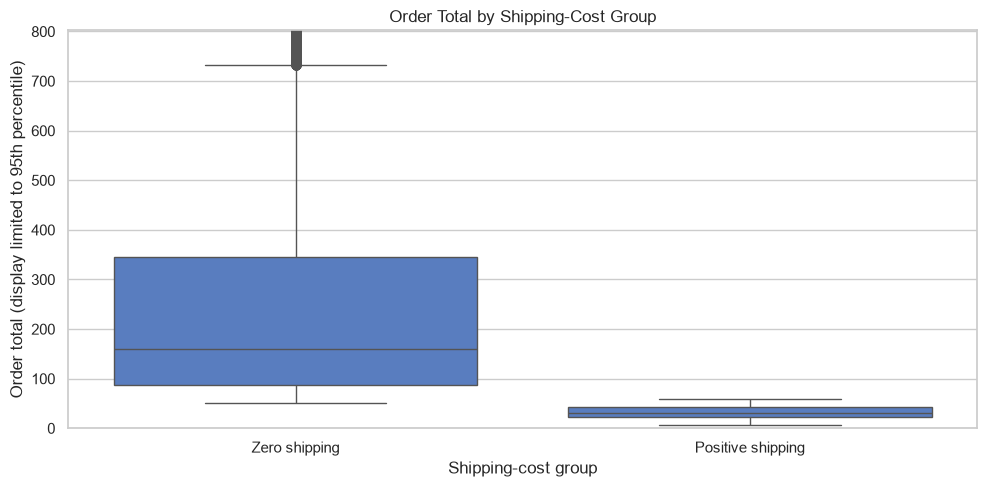

In [30]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="shipping_group",
    y="order_total"
)

plt.ylim(0, df["order_total"].quantile(0.95))
plt.title("Order Total by Shipping-Cost Group")
plt.xlabel("Shipping-cost group")
plt.ylabel("Order total (display limited to 95th percentile)")
plt.tight_layout()
plt.show()

**Result: Order-Value Distributions**

The boxplot complements the summary statistics by showing how strongly the order-value distributions differ between shipping groups. The comparison should be interpreted alongside the medians and quartiles, since limiting the plot to the 95th percentile hides the most extreme values from view.

### Analysis B — Return Status Across Order-Value Ranges and Shipping Groups

Divide order totals into fixed ranges and compare the observed returned-status percentages between shipping groups. Empty groups are retained in the summary but should not be interpreted as having a return rate of zero.

In [31]:
# Compare observed returned-status percentages across order-value ranges

value_bins = [0, 25, 50, 100, 200, 500, np.inf]
value_labels = [
    "0–25",
    "25–50",
    "50–100",
    "100–200",
    "200–500",
    "500+"
]

df["order_value_range"] = pd.cut(
    df["order_total"],
    bins=value_bins,
    labels=value_labels,
    right=False
)

shipping_value_analysis = (
    df.groupby(
        ["order_value_range", "shipping_group"],
        observed=False
    )
    .agg(
        order_count=("order_id", "size"),
        observed_returned_pct=(
            "is_marked_returned",
            lambda x: x.mean() * 100
        )
    )
    .reset_index()
)

display(
    shipping_value_analysis
    .sort_values(["order_value_range", "shipping_group"])
    .round(2)
)

,order_value_range,shipping_group,order_count,observed_returned_pct
0,0–25,Positive shipping,56771,3.58
1,0–25,Zero shipping,0,NaN
2,25–50,Positive shipping,98605,7.13
3,25–50,Zero shipping,0,NaN
4,50–100,Positive shipping,21372,9.30
5,50–100,Zero shipping,99918,10.66
6,100–200,Positive shipping,0,NaN
7,100–200,Zero shipping,88293,10.69
8,200–500,Positive shipping,0,NaN
9,200–500,Zero shipping,83624,10.55


**Result: Order Value and Shipping-Group Comparison**

The order-value ranges reveal a strong separation between the shipping groups. In this sample, zero-shipping orders do not appear in the ranges below 50, while positive-shipping orders do not appear in the ranges starting at 100.

Because the groups occupy different order-value ranges, a direct comparison of their overall return-status percentages can be misleading. The missing combinations in the table represent ranges with no observations, not zero return risk.

### Analysis C — Identifying Potential Shipping Thresholds

Examine the percentage of zero-shipping orders and the distribution of shipping costs across order-value ranges. This helps determine whether zero shipping is associated with particular order values and whether the pattern resembles a threshold-based rule.

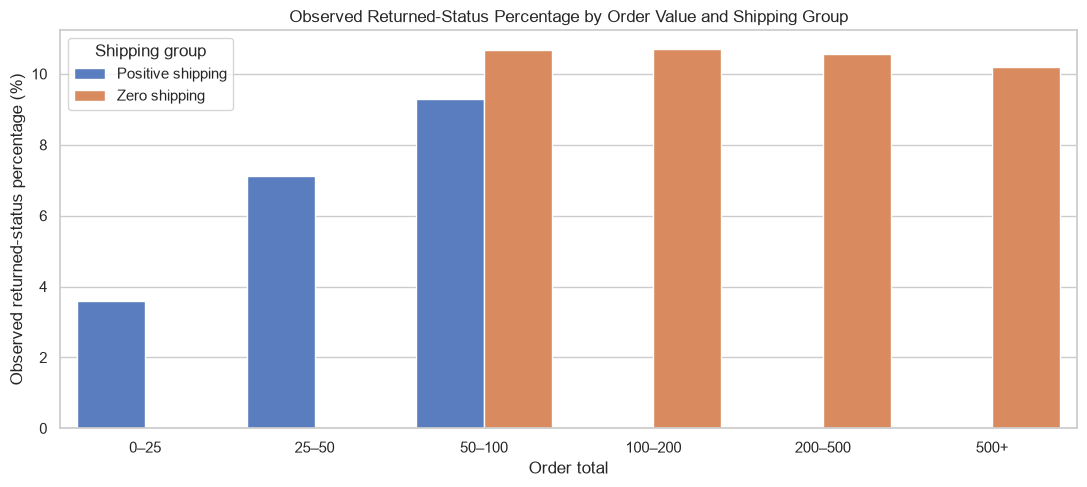

In [32]:
plot_data = shipping_value_analysis[
    shipping_value_analysis["order_count"] > 0
].copy()

plt.figure(figsize=(11, 5))

sns.barplot(
    data=plot_data,
    x="order_value_range",
    y="observed_returned_pct",
    hue="shipping_group",
    errorbar=None
)

plt.title("Observed Returned-Status Percentage by Order Value and Shipping Group")
plt.xlabel("Order total")
plt.ylabel("Observed returned-status percentage (%)")
plt.legend(title="Shipping group")
plt.tight_layout()
plt.show()

**Result: Shipping Patterns by Order Value**

The zero-shipping percentage varies sharply across order-value ranges. The lowest two ranges contain no zero-shipping orders, while the higher ranges show a different shipping-cost pattern.

This is consistent with a possible order-value-based shipping rule in the sampled data. However, the pattern alone does not establish the exact business rule or whether product category and other conditions also affect shipping eligibility.

### Examining the Shipping Transition at Individual Order Totals

Inspect individual order totals between 45 and 105 to locate where zero-shipping and positive-shipping records change in prevalence. This provides a more detailed check than grouping all orders into broad value ranges.

In [33]:
# Examine order-value ranges and their shipping-cost patterns

shipping_threshold_check = (
    df.groupby("order_value_range", observed=False)
    .agg(
        order_count=("order_id", "size"),
        min_order_total=("order_total", "min"),
        max_order_total=("order_total", "max"),
        zero_shipping_pct=(
            "shipping_cost",
            lambda x: x.eq(0).mean() * 100
        ),
        median_shipping_cost=("shipping_cost", "median"),
        min_shipping_cost=("shipping_cost", "min"),
        max_shipping_cost=("shipping_cost", "max")
    )
    .round(2)
)

display(shipping_threshold_check)

,order_count,min_order_total,max_order_total,zero_shipping_pct,median_shipping_cost,min_shipping_cost,max_shipping_cost
order_value_range,,,,,,,
0–25,56771,6.38,24.99,0.00,6.58,3.99,9.99
25–50,98605,25.00,49.99,0.00,7.07,3.99,9.99
50–100,121290,50.00,99.99,82.38,0.00,0.00,9.99
100–200,88293,100.00,199.99,100.00,0.00,0.00,0.00
200–500,83624,200.00,499.99,100.00,0.00,0.00,0.00
500+,51417,500.00,6172.80,100.00,0.00,0.00,0.00


**Result: Shipping Transition**

The displayed records show a transition from positive-shipping orders to zero-shipping orders within the inspected order-value interval. The percentage of zero-shipping orders changes from 0% at some lower totals to 100% at some higher totals.

This supports further investigation of a potential threshold-based shipping mechanism. The exact threshold should be established from the full transition pattern rather than inferred from a few rows.

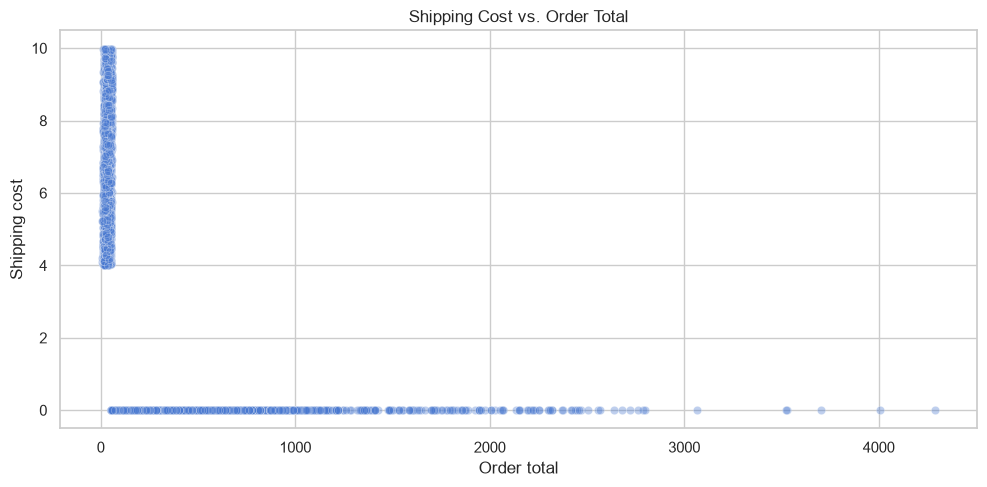

In [34]:
# Examine shipping cost against order total

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df.sample(n=min(5000, len(df)), random_state=42),
    x="order_total",
    y="shipping_cost",
    alpha=0.35
)

plt.title("Shipping Cost vs. Order Total")
plt.xlabel("Order total")
plt.ylabel("Shipping cost")
plt.tight_layout()
plt.show()

In [35]:
# Examine shipping behavior at distinct order totals

shipping_by_total = (
    df.groupby("order_total")
    .agg(
        order_count=("order_id", "size"),
        zero_shipping_pct=(
            "shipping_cost",
            lambda x: x.eq(0).mean() * 100
        ),
        min_shipping_cost=("shipping_cost", "min"),
        max_shipping_cost=("shipping_cost", "max")
    )
    .reset_index()
    .sort_values("order_total")
)

# Focus on the range where both shipping groups may occur
transition_orders = shipping_by_total[
    shipping_by_total["order_total"].between(45, 105)
]

display(transition_orders.round(2))

,order_total,order_count,zero_shipping_pct,min_shipping_cost,max_shipping_cost
3767,45.00,39,0.0,4.71,9.96
3768,45.01,34,0.0,4.06,9.96
3769,45.02,32,0.0,4.10,9.92
3770,45.03,35,0.0,4.11,9.93
3771,45.04,22,0.0,4.43,9.99
...,...,...,...,...,...
9762,104.96,20,100.0,0.00,0.00
9763,104.97,14,100.0,0.00,0.00
9764,104.98,13,100.0,0.00,0.00
9765,104.99,6,100.0,0.00,0.00


### Checking Shipping Patterns Within Product Categories

Compare zero-shipping percentages across both product categories and order-value ranges. This checks whether the observed shipping pattern is consistent across categories or whether some categories follow different patterns.

In [36]:
# Compare zero-shipping percentages across categories and value ranges

category_shipping_check = (
    df.groupby(
        ["product_category", "order_value_range"],
        observed=True
    )
    .agg(
        order_count=("order_id", "size"),
        zero_shipping_pct=(
            "shipping_cost",
            lambda x: x.eq(0).mean() * 100
        ),
        median_shipping_cost=("shipping_cost", "median")
    )
    .reset_index()
)

display(
    category_shipping_check
    .sort_values(["product_category", "order_value_range"])
    .round(2)
)

,product_category,order_value_range,order_count,zero_shipping_pct,median_shipping_cost
0,beauty,0–25,6484,0.00,6.46
1,beauty,25–50,20310,0.00,7.01
2,beauty,50–100,16176,76.00,0.00
3,beauty,100–200,6059,100.00,0.00
4,beauty,200–500,1045,100.00,0.00
5,books,0–25,19352,0.00,6.56
6,books,25–50,23059,0.00,7.26
7,books,50–100,10807,73.73,0.00
8,books,100–200,1492,100.00,0.00
9,books,200–500,11,100.00,0.00


**Result: Category-Specific Shipping Patterns**

The category-by-value-range table helps determine whether the relationship between order value and zero shipping is consistent across product categories. Differences between categories may indicate that shipping eligibility depends on more than order total alone.

The results should be interpreted alongside the overall shipping-threshold analysis, especially where individual category-range combinations contain relatively few orders.

## 4. Focused Analysis of Delivered and Returned Orders

For the next analysis, include only records with `order_status` equal to `delivered` or `returned`. Exclude shipped, processing, and cancelled orders because they do not represent the same outcome classes for this comparison.

Define `return_target` as 1 for returned orders and 0 for delivered orders. This target represents recorded order status, not independently verified customer return behavior.

In [37]:
# Define the target population for return analysis

labeled_df = df[
    df["order_status"].isin(["returned", "delivered"])
].copy()

labeled_df["return_target"] = (
    labeled_df["order_status"] == "returned"
).astype(int)

print("Orders in original sample:", len(df))
print("Orders included in target analysis:", len(labeled_df))
print("\nTarget counts:")
display(
    labeled_df["return_target"]
    .value_counts()
    .rename(index={0: "Delivered", 1: "Returned"})
    .to_frame("order_count")
)

print(
    "\nObserved return percentage in this analysis:",
    round(labeled_df["return_target"].mean() * 100, 2),
    "%"
)

Orders in original sample: 500000
Orders included in target analysis: 400012

Target counts:


,order_count
return_target,
Delivered,354803
Returned,45209



Observed return percentage in this analysis: 11.3 %


**Result: Analysis Population and Target Distribution**

The focused analysis contains 400,012 orders: 354,803 delivered and 45,209 returned. The observed returned-status percentage in this population is 11.30%.

This differs from the 9.04% returned-status proportion calculated over all 500,000 records because the denominator now excludes shipped, processing, and cancelled orders. The restricted target is more appropriate for comparing recorded outcomes between delivered and returned orders.

### Analysis D — Categorical Features and Recorded Return Outcomes

Compare the returned-status percentage across product categories, payment methods, and discount status within the focused analysis population. This provides a more consistent outcome comparison than the initial analysis over all order statuses.

In [38]:
# Compare categorical features with the recorded return target

categorical_features = [
    "product_category",
    "payment_method",
    "discount_applied"
]

for feature in categorical_features:
    summary = (
        labeled_df.groupby(feature, dropna=False)
        .agg(
            order_count=("return_target", "size"),
            returned_count=("return_target", "sum"),
            observed_return_pct=("return_target", "mean")
        )
        .sort_values("observed_return_pct", ascending=False)
    )

    summary["observed_return_pct"] *= 100

    print(f"\nFeature: {feature}")
    display(summary.round(2))


Feature: product_category


,order_count,returned_count,observed_return_pct
product_category,,,
clothing,87834,19490,22.19
electronics,63793,8771,13.75
sports,36072,3977,11.03
home,56402,4930,8.74
toys,32167,2593,8.06
beauty,40013,2928,7.32
books,43718,1731,3.96
grocery,40013,789,1.97



Feature: payment_method


,order_count,returned_count,observed_return_pct
payment_method,,,
bnpl,31778,3672,11.56
debit_card,96267,10941,11.37
credit_card,175993,19852,11.28
gift_card,23971,2695,11.24
paypal,72003,8049,11.18



Feature: discount_applied


,order_count,returned_count,observed_return_pct
discount_applied,,,
True,92177,10758,11.67
False,307835,34451,11.19


**Result: Categorical Return Patterns**

Product category shows substantial differences in the focused analysis. Clothing has the highest observed return percentage at 22.19%, followed by electronics at 13.75%. Grocery has the lowest percentage at 1.97%.

These differences suggest that product category may be an informative feature for a return-prediction model. The payment-method and discount comparisons provide additional descriptive evidence, but none of these associations establishes causality.

### Numerical Feature Comparison by Recorded Outcome

Compare the distributions of quantity, unit price, order total, and shipping cost between delivered and returned orders using summary statistics. Medians and means are both reported because the numerical features may be skewed.

In [39]:
# Compare numerical features between delivered and returned orders

numerical_features = [
    "quantity",
    "unit_price",
    "order_total",
    "shipping_cost"
]

numeric_summary = (
    labeled_df
    .groupby("return_target")[numerical_features]
    .agg(["count", "median", "mean", "std"])
)

numeric_summary.index = ["Delivered", "Returned"]

display(numeric_summary.round(2))

quantity                    unit_price                         \
             count median  mean   std      count median    mean     std   
Delivered   354803    1.0  1.92  1.25     354803  49.60  104.93  140.41   
Returned     45209    1.0  1.92  1.25      45209  65.52  122.19  147.93   

          order_total                         shipping_cost                     
                count  median    mean     std         count median  mean   std  
Delivered      354803   79.78  203.40  342.14        354803    0.0  2.56  3.53  
Returned        45209  106.18  236.33  373.91         45209    0.0  1.71  3.12

**Result: Numerical Differences Between Outcomes**

Returned orders have a higher median unit price (65.52) than delivered orders (49.60). Their median order total is also higher, at 106.18 compared with 79.78.

The mean quantity is the same in both groups, at 1.92. Mean shipping cost is lower for returned orders (1.71) than for delivered orders (2.56).

These differences suggest that price, order value, and shipping cost may help distinguish the recorded outcomes. They should be assessed together with categorical features and the potential shipping-threshold pattern.

### Visual Comparison of Numerical Features by Outcome

Use boxplots to compare numerical feature distributions for delivered and returned orders. The plots are restricted to the 95th percentile of each feature to improve readability while preserving the full data for the numerical summaries.

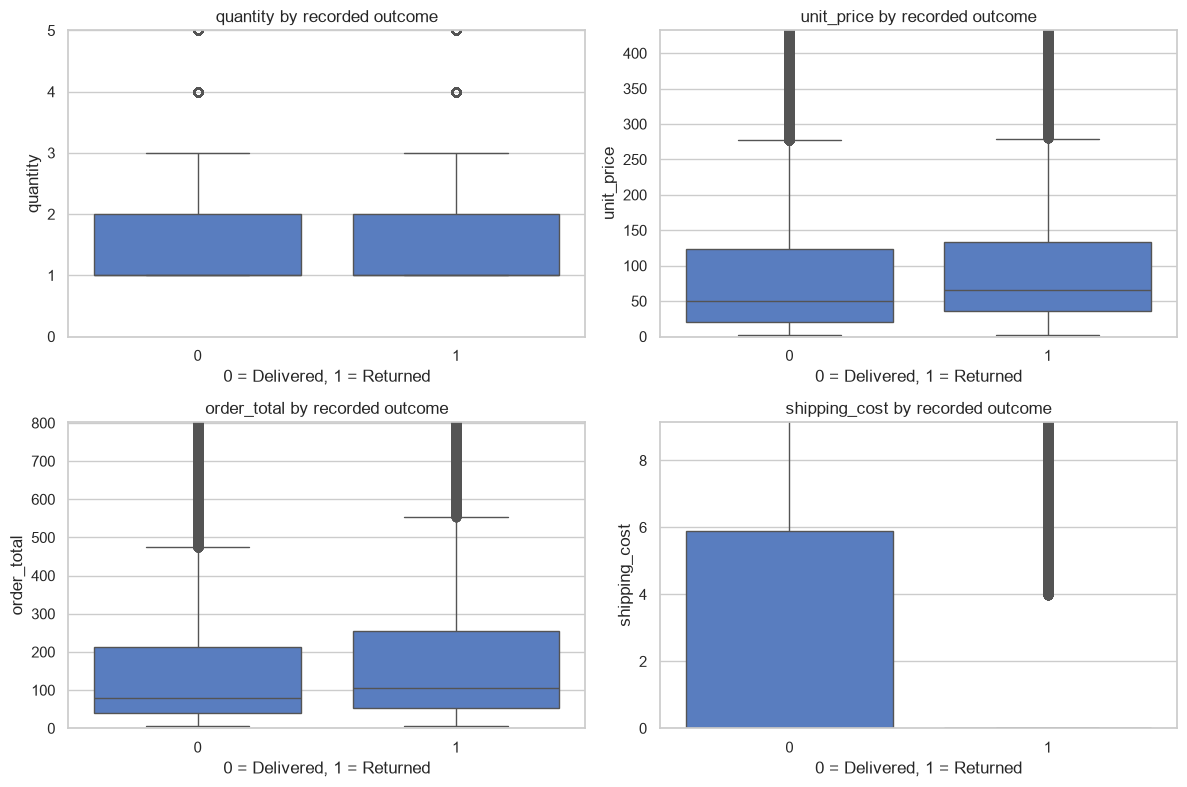

In [40]:
# Compare numerical feature distributions by recorded outcome

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(numerical_features, axes.flat):
    sns.boxplot(
        data=labeled_df,
        x="return_target",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} by recorded outcome")
    ax.set_xlabel("0 = Delivered, 1 = Returned")
    ax.set_ylabel(feature)

    # Limit the display to reduce the effect of extreme values
    upper_limit = labeled_df[feature].quantile(0.95)
    ax.set_ylim(bottom=0, top=upper_limit)

plt.tight_layout()
plt.show()

**Result: Numerical Distribution Plots**

The boxplots provide a visual check of the differences identified in the summary statistics. In particular, unit price and order total warrant attention because returned orders have higher median values.

The truncated axes make the central distributions easier to compare, but the plots do not display the full range of extreme values.

### Customer and Product Repetition

Examine how frequently customers and products appear in the focused analysis population. Repeated records can affect how a future model should split training and test data and how reliably product-level patterns can be estimated.

In [41]:
# Examine customer and product repetition

print("Orders in analysis population:", len(labeled_df))
print("Unique customers:", labeled_df["customer_id"].nunique())
print("Unique products:", labeled_df["product_id"].nunique())

customer_order_counts = labeled_df["customer_id"].value_counts()
product_order_counts = labeled_df["product_id"].value_counts()

print("\nCustomer repetition:")
print("Customers with multiple orders:",
      (customer_order_counts > 1).sum())
print("Maximum orders per customer:",
      customer_order_counts.max())

print("\nProduct repetition:")
print("Products appearing in multiple orders:",
      (product_order_counts > 1).sum())
print("Maximum orders per product:",
      product_order_counts.max())

print("\nCustomer orders per customer:")
display(customer_order_counts.describe().round(2).to_frame("orders_per_customer"))

print("\nProduct orders per product:")
display(product_order_counts.describe().round(2).to_frame("orders_per_product"))

Orders in analysis population: 400012
Unique customers: 392155
Unique products: 244914

Customer repetition:
Customers with multiple orders: 7753
Maximum orders per customer: 3

Product repetition:
Products appearing in multiple orders: 104988
Maximum orders per product: 10

Customer orders per customer:


,orders_per_customer
count,392155.00
mean,1.02
std,0.14
min,1.00
25%,1.00
50%,1.00
75%,1.00
max,3.00



Product orders per product:


,orders_per_product
count,244914.00
mean,1.63
std,0.89
min,1.00
25%,1.00
50%,1.00
75%,2.00
max,10.00


**Result: Customer and Product Repetition**

The focused population contains 392,155 unique customers and 244,914 unique products across 400,012 orders. Most customers appear once, although 7,753 customers have multiple orders. Products are repeated more frequently, with some appearing in up to 10 orders.

This repetition should be considered when designing validation. If the intended goal is to predict outcomes for previously unseen customers or products, a group-aware evaluation may be more appropriate than a simple random split.

### Product-Level Return Patterns

Examine recorded return percentages for products with a sufficient number of observations. A minimum order-count threshold helps avoid interpreting percentages based on very few orders, but the threshold must be chosen based on the observed frequency distribution.

In [42]:
# Summarize product-level observed return patterns

product_return_summary = (
    labeled_df
    .groupby("product_id")
    .agg(
        order_count=("return_target", "size"),
        returned_count=("return_target", "sum"),
        observed_return_pct=("return_target", "mean")
    )
    .reset_index()
)

# Focus on products with at least 30 orders
frequent_products = product_return_summary[
    product_return_summary["order_count"] >= 30
].copy()

print("Products with at least 30 orders:",
      len(frequent_products))

print("\nProducts with the highest observed return percentages:")
display(
    frequent_products
    .sort_values(
        ["observed_return_pct", "order_count"],
        ascending=[False, False]
    )
    .head(10)
    .assign(
        observed_return_pct=lambda x: x["observed_return_pct"] * 100
    )
    .round(2)
)

print("\nProducts with the lowest observed return percentages:")
display(
    frequent_products
    .sort_values(
        ["observed_return_pct", "order_count"],
        ascending=[True, False]
    )
    .head(10)
    .assign(
        observed_return_pct=lambda x: x["observed_return_pct"] * 100
    )
    .round(2)
)

Products with at least 30 orders: 0

Products with the highest observed return percentages:


,product_id,order_count,returned_count,observed_return_pct



Products with the lowest observed return percentages:


,product_id,order_count,returned_count,observed_return_pct


## 5. Temporal Trends in Recorded Returns

Examine monthly order-status counts and calculate the observed returned-status percentage among delivered and returned orders. Using the restricted population keeps the monthly return-rate denominator consistent with the focused outcome analysis.

In [43]:
# Examine monthly order statuses and observed return percentages

df["order_month"] = df["order_date"].dt.to_period("M")

monthly_status_counts = pd.crosstab(
    df["order_month"],
    df["order_status"]
)

display(monthly_status_counts)

# Use only returned and delivered orders for this comparison
monthly_labeled = labeled_df.copy()
monthly_labeled["order_month"] = (
    monthly_labeled["order_date"].dt.to_period("M")
)

monthly_return_summary = (
    monthly_labeled
    .groupby("order_month")
    .agg(
        order_count=("return_target", "size"),
        returned_count=("return_target", "sum"),
        observed_return_pct=("return_target", "mean")
    )
)

monthly_return_summary["observed_return_pct"] *= 100

display(monthly_return_summary.round(2))

order_status,cancelled,delivered,processing,returned,shipped
order_month,,,,,
2024-01,833,14926,1257,1851,2129
2024-02,745,14093,1210,1872,1984
2024-03,888,15188,1270,1927,2158
2024-04,784,14325,1174,1842,2074
2024-05,879,15142,1244,1906,2104
2024-06,839,14496,1228,1881,2034
2024-07,882,15078,1354,1953,2098
2024-08,844,15192,1293,1858,2078
2024-09,799,14587,1193,1795,2069


,order_count,returned_count,observed_return_pct
order_month,,,
2024-01,16777,1851,11.03
2024-02,15965,1872,11.73
2024-03,17115,1927,11.26
2024-04,16167,1842,11.39
2024-05,17048,1906,11.18
2024-06,16377,1881,11.49
2024-07,17031,1953,11.47
2024-08,17050,1858,10.90
2024-09,16382,1795,10.96


**Result: Monthly Order and Return Summary**

The monthly status table provides a view of order volume and status composition over the observation period. The focused monthly summary separately tracks the number of delivered and returned orders and their observed returned-status percentage.

Comparing monthly percentages is more informative than comparing returned-order counts alone, because the number of orders varies across months.

### Monthly Observed Return Percentage

Plot the monthly observed returned-status percentage for delivered and returned orders. This helps identify temporal fluctuations and potential changes in the outcome distribution during the observation period.

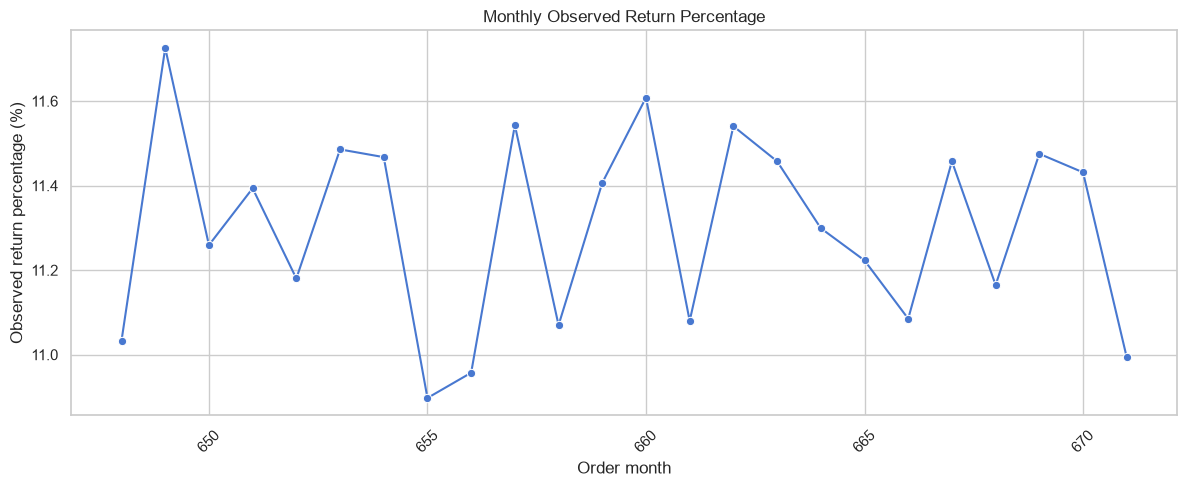

In [44]:
# Visualize monthly observed return percentages

monthly_plot = monthly_return_summary.reset_index()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_plot,
    x="order_month",
    y="observed_return_pct",
    marker="o"
)

plt.title("Monthly Observed Return Percentage")
plt.xlabel("Order month")
plt.ylabel("Observed return percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Result: Monthly Return Trend**

The line plot shows how the observed returned-status percentage varies over time. The monthly trend should be interpreted as a descriptive pattern rather than evidence of seasonality or a causal time effect.

Any apparent peaks or dips should be assessed alongside monthly order counts to determine whether they reflect substantial changes or ordinary fluctuations.